# Data storytelling: from an exploratory chart to an explanatory one (COVID-19, first half of 2020)
**Data.** WHO daily case and death reports for 216 countries and territories, January-July 2020, plus population from the CIA World Factbook.

**What this demonstrates.** The analytical steps that turn a spaghetti chart into a chart that makes a point: joining a reference table with inconsistent country names, normalising by population, smoothing reporting noise, aligning countries on the outbreak timeline instead of the calendar, and designing the final chart (direct labels, a single highlighted message, honest scales).

> The period covers the first wave only and reflects testing and reporting practices at the time. Counts are *reported* cases and deaths, not true infections.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
w = pd.read_csv("data/who_covid_2020H1.csv", parse_dates=["Date_reported"])
pop = pd.read_csv("data/factbook_population.csv")
print(w.shape, w.Date_reported.min().date(), w.Date_reported.max().date(), w.Country.nunique(), "countries")

(31876, 6) 2020-01-04 2020-07-31 216 countries


In [2]:
fix = {"United States of America": "United States", "The United Kingdom": "United Kingdom", "Russian Federation": "Russia", "Iran (Islamic Republic of)": "Iran",
       "Republic of Korea": "Korea, South", "Viet Nam": "Vietnam", "Czechia": "Czech Republic", "Bolivia (Plurinational State of)": "Bolivia",
       "Venezuela (Bolivarian Republic of)": "Venezuela", "Syrian Arab Republic": "Syria", "Republic of Moldova": "Moldova", "North Macedonia": "Macedonia",
       "United Republic of Tanzania": "Tanzania", "Côte d’Ivoire": "Cote d'Ivoire", "Lao People's Democratic Republic": "Laos", "Myanmar": "Burma",
       "Brunei Darussalam": "Brunei", "Bahamas": "Bahamas, The", "Gambia": "Gambia, The", "Eswatini": "Swaziland", "Kosovo[1]": "Kosovo",
       "Democratic Republic of the Congo": "Congo, Democratic Republic of the", "Congo": "Congo, Republic of the", "Holy See": "Holy See (Vatican City)"}
w["country_std"] = w.Country.replace(fix)
before = w.Country.isin(pop.name).groupby(w.Country).first().mean()
d = w.merge(pop, left_on="country_std", right_on="name", how="left")
after = d.population.notna().groupby(d.Country).first().mean()
print(f"countries matched to a population: {before:.0%} by exact name -> {after:.0%} after a {len(fix)}-entry mapping")
print("still unmatched (overseas territories, cruise ships):", sorted(d[d.population.isna()].Country.unique())[:8], "...")
d = d.dropna(subset=["population"])
d["deaths_7d_per_m"] = d.groupby("Country").New_deaths.transform(lambda s: s.rolling(7).mean()) / d.population * 1e6
d["cum_deaths_per_m"] = d.Cumulative_deaths / d.population * 1e6

countries matched to a population: 83% by exact name -> 94% after a 24-entry mapping
still unmatched (overseas territories, cruise ships): ['Bonaire, Sint Eustatius and Saba', 'Curaçao', 'Falkland Islands (Malvinas)', 'French Guiana', 'Guadeloupe', 'Martinique', 'Mayotte', 'Northern Mariana Islands (Commonwealth of the)'] ...


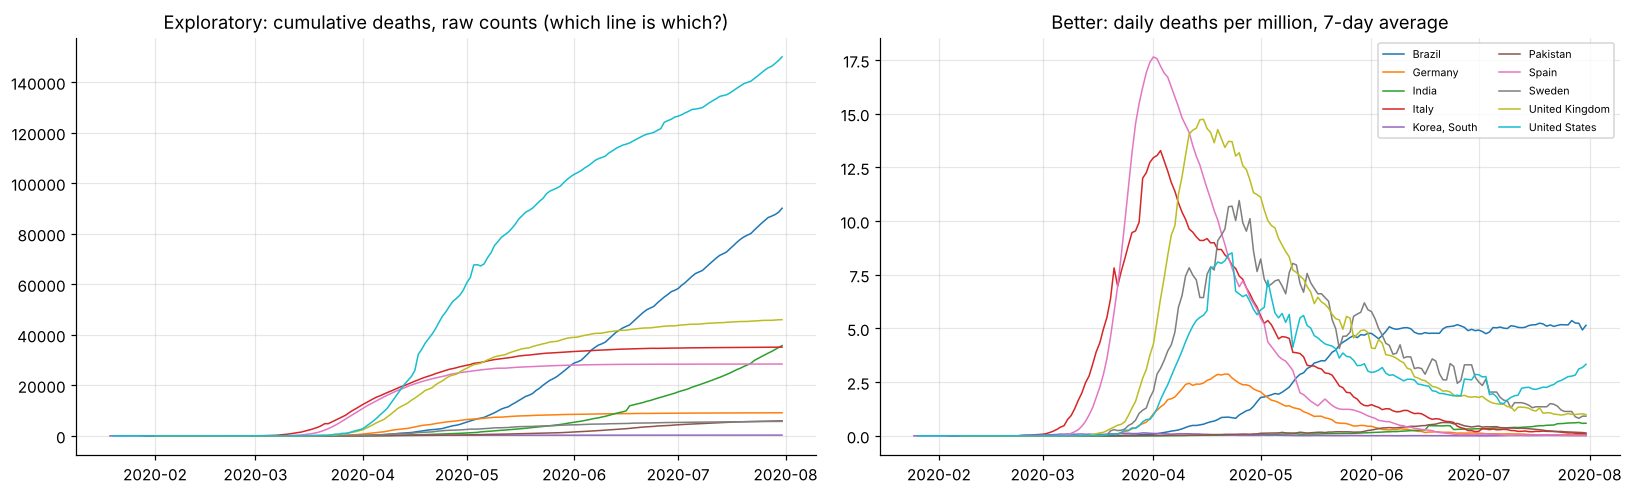

In [3]:
focus = ["United States", "United Kingdom", "Italy", "Spain", "Sweden", "Germany", "Brazil", "India", "Pakistan", "Korea, South"]
f = d[d.country_std.isin(focus)]
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for c, g in f.groupby("country_std"): axes[0].plot(g.Date_reported, g.Cumulative_deaths, lw=1)
axes[0].set_title("Exploratory: cumulative deaths, raw counts (which line is which?)")
for c, g in f.groupby("country_std"): axes[1].plot(g.Date_reported, g.deaths_7d_per_m, lw=1, label=c)
axes[1].set_title("Better: daily deaths per million, 7-day average"); axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(IMG / "exploratory.png", bbox_inches="tight"); plt.show()

## Align on the outbreak, not the calendar
Day 0 is the first day a country reached 0.1 cumulative deaths per million people. This removes the weeks of difference in *when* each epidemic began.

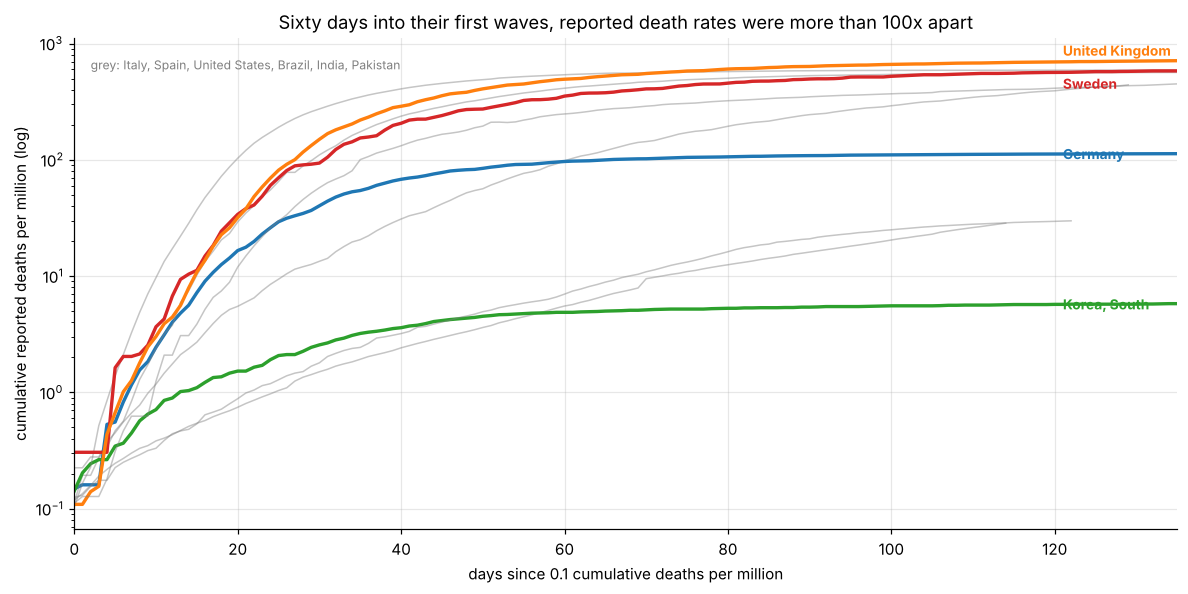

country_std
Korea, South        4.9
India               5.5
Pakistan            7.0
Germany            96.8
Brazil             98.1
United States     247.8
Sweden            353.0
Italy             413.0
United Kingdom    493.2
Spain             538.9
Name: cum_deaths_per_m, dtype: float64

In [4]:
def align(g):
    g = g.sort_values("Date_reported"); start = g.loc[g.cum_deaths_per_m >= 0.1, "Date_reported"]
    if start.empty: return None
    g = g[g.Date_reported >= start.iloc[0]].copy(); g["day"] = (g.Date_reported - start.iloc[0]).dt.days; return g
al = pd.concat([align(g) for _, g in f.groupby("country_std") if align(g) is not None])
d60 = al[al.day == 60].set_index("country_std")["cum_deaths_per_m"].sort_values()
fig, ax = plt.subplots(figsize=(11, 5.5))
highlight = {"Korea, South": "C2", "Sweden": "C3", "Germany": "C0", "United Kingdom": "C1"}
for c, g in al.groupby("country_std"):
    col, lw, a = (highlight[c], 2.2, 1) if c in highlight else ("grey", 1, .45)
    ax.plot(g.day, g.cum_deaths_per_m, color=col, lw=lw, alpha=a)
    if c in highlight:
        last = g[g.day <= 120].iloc[-1]; ax.text(last.day + 1, last.cum_deaths_per_m * (1.25 if c == "United Kingdom" else 0.8 if c == "Sweden" else 1), c, color=col, fontsize=9, va="center", fontweight="bold")
ax.set_yscale("log"); ax.set_xlim(0, 135); ax.set_xlabel("days since 0.1 cumulative deaths per million")
ax.set_ylabel("cumulative reported deaths per million (log)")
ax.set_title("Sixty days into their first waves, reported death rates were more than 100x apart")
ax.text(2, 600, "grey: Italy, Spain, United States, Brazil, India, Pakistan", fontsize=8, color="grey")
for s_ in ["top", "right"]: ax.spines[s_].set_visible(False)
plt.tight_layout(); plt.savefig(IMG / "explanatory.png", bbox_inches="tight"); plt.show()
d60.round(1)

## Findings
* **Joining data is half the work:** only 83% of WHO country names match the Factbook exactly. A 24-entry mapping (e.g. "Viet Nam" to "Vietnam", "Republic of Korea" to "Korea, South") lifts that to 94%. The rest are overseas territories and cruise ships without a separate population.
* **Normalise, smooth, align.** Raw cumulative counts mostly show which countries are big. Deaths per million, a 7-day average and a common "day 0" turn the same data into a comparison of epidemics.
* **The message the final chart carries:** 60 days after reaching 0.1 deaths per million, reported deaths ranged from **4.9 per million (South Korea)** and 5.5 (India) to 493 (United Kingdom) and 539 (Spain), a difference of more than 100×. Germany (97) and Sweden (353) show how far neighbouring countries diverged.
* **Design choices:** one highlighted message, direct labels instead of a legend, a log scale stated on the axis, and caveats about reporting kept next to the chart.